# Referência

https://www.researchgate.net/publication/223556476_Wavelet_filter-based_weak_signature_detection_method_and_its_application_on_rolling_element_bearing_prognostics

The time domain feature also shows that most of the bearing fatigue time is consumed duringthe period of material accumulative damage, while the period of crack propagation and development is relatively short. This means that if the traditional threshold-based condition monitoring approach is used, the response time available for the maintenance crew to respond prior to catastrophic failure after a defect is detected in such bearings is very short. A prognostic approach that can detect the defect at the early stage is demanded so that enough buffer time is available for maintenance and logistical scheduling. This requirement is extremely important for some mission-critical situations, such as power plants and continuous production lines.

# Bibliotecas

In [174]:
from google.colab import drive
import pandas as pd
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

# Dataset

In [34]:
# Acesso ao Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
df_rolamentos = pd.read_csv('/content/drive/MyDrive/Datasets/NASA Acoustics and Vibration Database/df_rolamento_2nd_test.csv',
                            sep=',',
                            encoding='utf-8')

df_rolamentos.index = pd.to_datetime(df_rolamentos['t_stamp'],
                                     format='%Y-%m-%d %H:%M:%S').sort_values()

df_rolamentos.drop(columns=['t_stamp'], inplace=True)

df_rolamentos.head()

,bearing_1,bearing_2,bearing_3,bearing_4
t_stamp,,,,
2004-02-12 10:32:39,0.061630,0.075284,0.080999,0.044688
2004-02-12 10:42:39,0.058333,0.071832,0.083242,0.043067
2004-02-12 10:52:39,0.061231,0.074172,0.082022,0.043840
2004-02-12 11:02:39,0.058995,0.074006,0.084435,0.044541
2004-02-12 11:12:39,0.062599,0.075488,0.080626,0.044679


In [36]:
fig = make_subplots(rows=4,
                    cols=1,
                    subplot_titles=('Rolamento 1',
                                    'Rolamento 2',
                                    'Rolamento 3',
                                    'Rolamento 4'),
                    shared_xaxes=True)

fig.add_trace(go.Scatter(x=df_rolamentos.index,
                         y=df_rolamentos['bearing_1']),
              row=1, col=1)

fig.add_trace(go.Scatter(x=df_rolamentos.index,
                         y=df_rolamentos['bearing_2']),
              row=2, col=1)

fig.add_trace(go.Scatter(x=df_rolamentos.index,
                         y=df_rolamentos['bearing_3']),
              row=3, col=1)

fig.add_trace(go.Scatter(x=df_rolamentos.index,
                         y=df_rolamentos['bearing_4']),
              row=4, col=1)

fig.update_layout(height=900,
                  width=1200,
                  showlegend=False)

fig.update_yaxes(title_text='RMS vibration',row=1)

fig.update_yaxes(title_text='RMS vibration', row=2)

fig.update_yaxes(title_text='RMS vibration', row=3)

fig.update_yaxes(title_text='RMS vibration', row=4)

fig.show()

# Treshold

In [37]:
treshold = 0.1

# Dataset rolamento 1

In [38]:
df_rolamento_1 = pd.DataFrame(df_rolamentos['bearing_1'])

df_rolamento_1.head()

,bearing_1
t_stamp,
2004-02-12 10:32:39,0.061630
2004-02-12 10:42:39,0.058333
2004-02-12 10:52:39,0.061231
2004-02-12 11:02:39,0.058995
2004-02-12 11:12:39,0.062599


## Agrupamentos

In [39]:
df_rolamento_1_15_min = df_rolamento_1.groupby(pd.Grouper(freq='15min')).mean()

df_rolamento_1_hora = df_rolamento_1.groupby(pd.Grouper(freq='1h')).mean()

df_rolamento_1_dia = df_rolamento_1.groupby(pd.Grouper(freq='1d')).mean()

In [40]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_rolamento_1.index,
                         y=df_rolamento_1['bearing_1'],
                         mode='lines',
                         name='Dados originais',
                         line=dict(color='#000000 ')))

fig.add_trace(go.Scatter(x=df_rolamento_1_15_min.index,
                         y=df_rolamento_1_15_min['bearing_1'],
                         name='Agrupamento 15 min',
                         mode='lines',
                         line=dict(color='darkblue')))

fig.add_trace(go.Scatter(x=df_rolamento_1_hora.index,
                         y=df_rolamento_1_hora['bearing_1'],
                         name='Agrupamento hora',
                         mode='lines',
                         line=dict(color='#6b8e23')))

fig.add_trace(go.Scatter(x=df_rolamento_1_dia.index,
                         y=df_rolamento_1_dia['bearing_1'],
                         name='Agrupamento dia',
                         mode='lines',
                         line=dict(color='#d51920')))

fig.update_layout(legend=dict(yanchor='top',
                              y=0.95,
                              xanchor='left',
                              x=0.01),
                  title='Rolamento 1')

fig.add_hline(y=treshold,
              line_dash='dash',
              line_color='red',
              line_width=1)

fig.show()

## Dataset pré-falha

In [41]:
primeira_ocorrencia_acima_treshold_rolamento_1 = df_rolamento_1.loc[df_rolamento_1['bearing_1'] > treshold].index.values[0]

df_pre_falha_1 = df_rolamento_1.copy()

df_pre_falha_1 = df_pre_falha_1.loc[df_pre_falha_1.index < primeira_ocorrencia_acima_treshold_rolamento_1]

df_pre_falha_1

,bearing_1
t_stamp,
2004-02-12 10:32:39,0.061630
2004-02-12 10:42:39,0.058333
2004-02-12 10:52:39,0.061231
2004-02-12 11:02:39,0.058995
2004-02-12 11:12:39,0.062599
...,...
2004-02-17 04:32:39,0.080571
2004-02-17 04:42:39,0.080632
2004-02-17 04:52:39,0.081551


## Dataset falha

In [88]:
df_falha_1 = df_rolamento_1.copy()

df_falha_1 = df_falha_1.loc[df_falha_1.index >= primeira_ocorrencia_acima_treshold_rolamento_1]

df_falha_1

,bearing_1
t_stamp,
2004-02-17 05:22:39,0.117351
2004-02-17 05:32:39,0.082790
2004-02-17 05:42:39,0.118444
2004-02-17 05:52:39,0.081075
2004-02-17 06:02:39,0.080850
...,...
2004-02-19 05:42:39,0.001857
2004-02-19 05:52:39,0.351952
2004-02-19 06:02:39,0.294231


# Dataset rolamento 2

In [42]:
df_rolamento_2 = pd.DataFrame(df_rolamentos['bearing_2'])

df_rolamento_2.head()

,bearing_2
t_stamp,
2004-02-12 10:32:39,0.075284
2004-02-12 10:42:39,0.071832
2004-02-12 10:52:39,0.074172
2004-02-12 11:02:39,0.074006
2004-02-12 11:12:39,0.075488


## Agrupamentos

In [43]:
df_rolamento_2_15_min = df_rolamento_2.groupby(pd.Grouper(freq='15min')).mean()

df_rolamento_2_hora = df_rolamento_2.groupby(pd.Grouper(freq='1h')).mean()

df_rolamento_2_dia = df_rolamento_2.groupby(pd.Grouper(freq='1d')).mean()

In [44]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_rolamento_2.index,
                         y=df_rolamento_2['bearing_2'],
                         mode='lines',
                         name='Dados originais',
                         line=dict(color='#000000 ')))

fig.add_trace(go.Scatter(x=df_rolamento_2_15_min.index,
                         y=df_rolamento_2_15_min['bearing_2'],
                         name='Agrupamento 15 min',
                         mode='lines',
                         line=dict(color='darkblue')))

fig.add_trace(go.Scatter(x=df_rolamento_2_hora.index,
                         y=df_rolamento_2_hora['bearing_2'],
                         name='Agrupamento hora',
                         mode='lines',
                         line=dict(color='#6b8e23')))

fig.add_trace(go.Scatter(x=df_rolamento_2_dia.index,
                         y=df_rolamento_2_dia['bearing_2'],
                         name='Agrupamento dia',
                         mode='lines',
                         line=dict(color='#d51920')))

fig.update_layout(legend=dict(yanchor='top',
                              y=0.95,
                              xanchor='left',
                              x=0.01),
                  title='Rolamento 2')

fig.add_hline(y=treshold,
              line_dash='dash',
              line_color='red',
              line_width=1)

fig.show()

## Dataset pré-falha

In [45]:
primeira_ocorrencia_acima_treshold_rolamento_2 = df_rolamento_2.loc[df_rolamento_2['bearing_2'] > treshold].index.values[0]

df_pre_falha_2 = df_rolamento_2.copy()

df_pre_falha_2 = df_pre_falha_2.loc[df_pre_falha_2.index < primeira_ocorrencia_acima_treshold_rolamento_2]

df_pre_falha_2

,bearing_2
t_stamp,
2004-02-12 10:32:39,0.075284
2004-02-12 10:42:39,0.071832
2004-02-12 10:52:39,0.074172
2004-02-12 11:02:39,0.074006
2004-02-12 11:12:39,0.075488
...,...
2004-02-18 18:42:39,0.086469
2004-02-18 18:52:39,0.088622
2004-02-18 19:02:39,0.095112


# Dataset rolamento 3

In [46]:
df_rolamento_3 = pd.DataFrame(df_rolamentos['bearing_3'])

df_rolamento_3.head()

,bearing_3
t_stamp,
2004-02-12 10:32:39,0.080999
2004-02-12 10:42:39,0.083242
2004-02-12 10:52:39,0.082022
2004-02-12 11:02:39,0.084435
2004-02-12 11:12:39,0.080626


## Agrupamentos

In [47]:
df_rolamento_3_15_min = df_rolamento_3.groupby(pd.Grouper(freq='15min')).mean()

df_rolamento_3_hora = df_rolamento_3.groupby(pd.Grouper(freq='1h')).mean()

df_rolamento_3_dia = df_rolamento_3.groupby(pd.Grouper(freq='1d')).mean()

In [48]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_rolamento_3.index,
                         y=df_rolamento_3['bearing_3'],
                         mode='lines',
                         name='Dados originais',
                         line=dict(color='#000000 ')))

fig.add_trace(go.Scatter(x=df_rolamento_3_15_min.index,
                         y=df_rolamento_3_15_min['bearing_3'],
                         name='Agrupamento 15 min',
                         mode='lines',
                         line=dict(color='darkblue')))

fig.add_trace(go.Scatter(x=df_rolamento_3_hora.index,
                         y=df_rolamento_3_hora['bearing_3'],
                         name='Agrupamento hora',
                         mode='lines',
                         line=dict(color='#6b8e23')))

fig.add_trace(go.Scatter(x=df_rolamento_3_dia.index,
                         y=df_rolamento_3_dia['bearing_3'],
                         name='Agrupamento dia',
                         mode='lines',
                         line=dict(color='#d51920')))

fig.update_layout(legend=dict(yanchor='top',
                              y=0.95,
                              xanchor='left',
                              x=0.01),
                  title='Rolamento 3')

fig.add_hline(y=treshold,
              line_dash='dash',
              line_color='red',
              line_width=1)

fig.show()

## Dataset pré-falha

In [49]:
primeira_ocorrencia_acima_treshold_rolamento_3 = df_rolamento_3.loc[df_rolamento_3['bearing_3'] > treshold].index.values[0]

df_pre_falha_3 = df_rolamento_3.copy()

df_pre_falha_3 = df_pre_falha_3.loc[df_pre_falha_3.index < primeira_ocorrencia_acima_treshold_rolamento_3]

df_pre_falha_3

,bearing_3
t_stamp,
2004-02-12 10:32:39,0.080999
2004-02-12 10:42:39,0.083242
2004-02-12 10:52:39,0.082022
2004-02-12 11:02:39,0.084435
2004-02-12 11:12:39,0.080626
...,...
2004-02-18 14:52:39,0.084785
2004-02-18 15:02:39,0.084666
2004-02-18 15:12:39,0.085198


# Dataset rolamento 4

In [50]:
df_rolamento_4 = pd.DataFrame(df_rolamentos['bearing_4'])

df_rolamento_4.head()

,bearing_4
t_stamp,
2004-02-12 10:32:39,0.044688
2004-02-12 10:42:39,0.043067
2004-02-12 10:52:39,0.043840
2004-02-12 11:02:39,0.044541
2004-02-12 11:12:39,0.044679


## Agrupamentos

In [51]:
df_rolamento_4_15_min = df_rolamento_4.groupby(pd.Grouper(freq='15min')).mean()

df_rolamento_4_hora = df_rolamento_4.groupby(pd.Grouper(freq='1h')).mean()

df_rolamento_4_dia = df_rolamento_4.groupby(pd.Grouper(freq='1d')).mean()

In [52]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=df_rolamento_4.index,
                         y=df_rolamento_4['bearing_4'],
                         mode='lines',
                         name='Dados originais',
                         line=dict(color='#000000 ')))

fig.add_trace(go.Scatter(x=df_rolamento_4_15_min.index,
                         y=df_rolamento_4_15_min['bearing_4'],
                         name='Agrupamento 15 min',
                         mode='lines',
                         line=dict(color='darkblue')))

fig.add_trace(go.Scatter(x=df_rolamento_4_hora.index,
                         y=df_rolamento_4_hora['bearing_4'],
                         name='Agrupamento hora',
                         mode='lines',
                         line=dict(color='#6b8e23')))

fig.add_trace(go.Scatter(x=df_rolamento_4_dia.index,
                         y=df_rolamento_4_dia['bearing_4'],
                         name='Agrupamento dia',
                         mode='lines',
                         line=dict(color='#d51920')))

fig.update_layout(legend=dict(yanchor='top',
                              y=0.95,
                              xanchor='left',
                              x=0.01),
                  title='Rolamento 4')

fig.add_hline(y=treshold,
              line_dash='dash',
              line_color='red',
              line_width=1)

fig.show()

## Dataset pré-falha

In [53]:
primeira_ocorrencia_acima_treshold_rolamento_4 = df_rolamento_4.loc[df_rolamento_4['bearing_4'] > treshold].index.values[0]

df_pre_falha_4 = df_rolamento_4.copy()

df_pre_falha_4 = df_pre_falha_4.loc[df_pre_falha_4.index < primeira_ocorrencia_acima_treshold_rolamento_4]

df_pre_falha_4

,bearing_4
t_stamp,
2004-02-12 10:32:39,0.044688
2004-02-12 10:42:39,0.043067
2004-02-12 10:52:39,0.043840
2004-02-12 11:02:39,0.044541
2004-02-12 11:12:39,0.044679
...,...
2004-02-19 03:02:39,0.076731
2004-02-19 03:12:39,0.074150
2004-02-19 03:22:39,0.087876


# Previsão de valores

* Árvore de decisão
* Support Vector Machine
* Random forest

* Classificar o dataset em "falha", "pré-falha" ou "normal"
* Aplicar OneHot Encoder


## SVM

In [128]:
treino_start_dt_rolamento_1 = df_pre_falha_1.index[0]
teste_start_dt_rolamento_1 = df_falha_1.index[0]

In [129]:
treino_start_dt_rolamento_1

Timestamp('2004-02-12 10:32:39')

In [130]:
teste_start_dt_rolamento_1

Timestamp('2004-02-17 05:22:39')

<Axes: xlabel='t_stamp'>

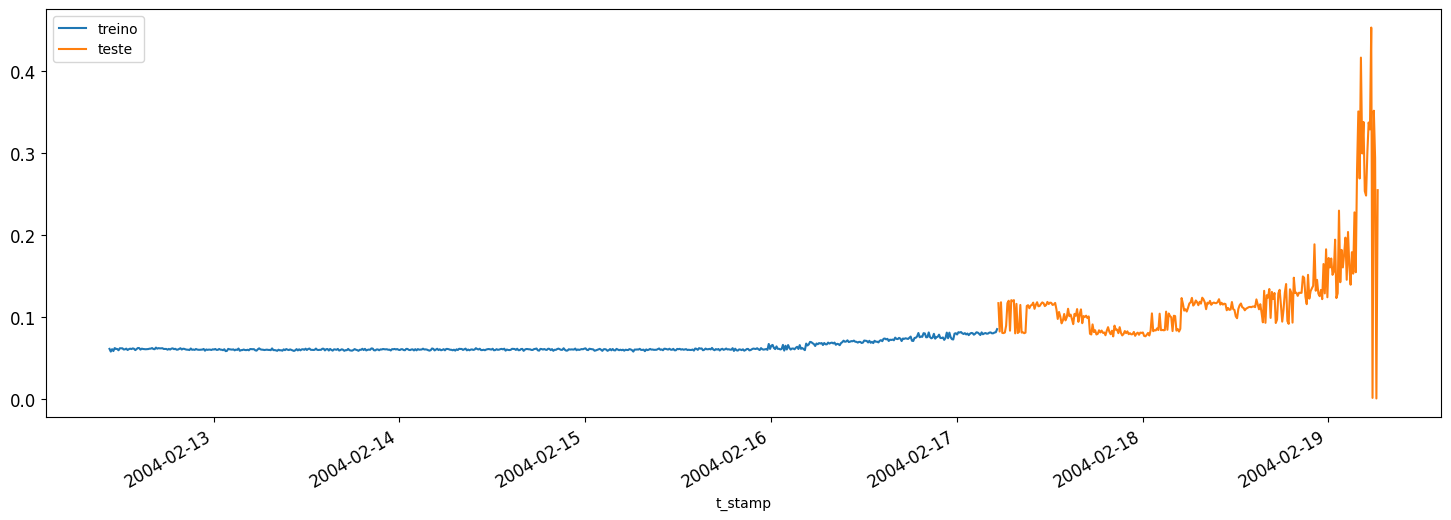

In [131]:
df_rolamento_1[(df_rolamento_1.index < teste_start_dt_rolamento_1) & (df_rolamento_1.index >= treino_start_dt_rolamento_1)][['bearing_1']].rename(columns={'bearing_1':'treino'}) \
    .join(df_rolamento_1[teste_start_dt_rolamento_1:][['bearing_1']].rename(columns={'bearing_1':'teste'}), how='outer') \
    .plot(y=['treino', 'teste'], figsize=(18, 6), fontsize=12)

In [133]:
treino_rolamento_1 = df_rolamento_1.copy()[(df_rolamento_1.index >= treino_start_dt_rolamento_1) & (df_rolamento_1.index < teste_start_dt_rolamento_1)][['bearing_1']]
teste_rolamento_1 = df_rolamento_1.copy()[df_rolamento_1.index >= teste_start_dt_rolamento_1][['bearing_1']]

print('treino_rolamento_1 data shape: ', treino_rolamento_1.shape)
print('teste_rolamento_1 data shape: ', teste_rolamento_1.shape)

treino_rolamento_1 data shape:  (689, 1)
teste_rolamento_1 data shape:  (295, 1)


In [134]:
scaler = MinMaxScaler()
treino_rolamento_1['bearing_1'] = scaler.fit_transform(treino_rolamento_1)
teste_rolamento_1['bearing_1'] = scaler.fit_transform(teste_rolamento_1)

## Suport Vector Regression (SVR)

In [141]:
# Conversão para numpy arrays
treino_data_rolamento_1 = treino_rolamento_1.values
teste_data_rolamento_1 = teste_rolamento_1.values

### Timesteps

In [208]:
timesteps = 5

In [209]:
# Conversão treino data to 2D tensor
treino_data_timesteps_rolamento_1 = np.array([[j for j in treino_data_rolamento_1[i:i+timesteps]] for i in range(0,len(treino_data_rolamento_1)-timesteps+1)])[:,:,0]
print(treino_data_timesteps_rolamento_1.shape)

# Conversão testing data to 2D tensor
teste_data_timesteps_rolamento_1 = np.array([[j for j in teste_data_rolamento_1[i:i+timesteps]] for i in range(0,len(teste_data_rolamento_1)-timesteps+1)])[:,:,0]
print(teste_data_timesteps_rolamento_1.shape)

(685, 5)
(291, 5)


In [210]:
# Selecting inputs and outputs from training and testing data
x_treino_rolamento_1, y_treino_rolamento_1 = treino_data_timesteps_rolamento_1[:,:timesteps-1],treino_data_timesteps_rolamento_1[:,[timesteps-1]]
print(x_treino_rolamento_1.shape, y_treino_rolamento_1.shape)

x_teste_rolamento_1, y_teste_rolamento_1 = teste_data_timesteps_rolamento_1[:,:timesteps-1],teste_data_timesteps_rolamento_1[:,[timesteps-1]]
print(x_teste_rolamento_1.shape, y_teste_rolamento_1.shape)

(685, 4) (685, 1)
(291, 4) (291, 1)


Radial Basis Function (RBF) kernel, which is a popular choice for SVMs due to its flexibility and ability to capture complex relationships between the input and output variables. The RBF kernel has two important parameters: gamma and C (also called regularization parameter). Gamma is a parameter that determines the width of the kernel function, and C is a regularization parameter that controls the trade-off between achieving a good fit to the training data and a simple decision boundary. The choice of these parameters can significantly impact the performance of an SVM model, making it important to tune them carefully.

In [211]:
model_rolamento_1 = SVR(kernel='rbf', gamma=0.5, C=10, epsilon=0.05)

In [212]:
# Fit the model on training data 1
model_rolamento_1.fit(x_treino_rolamento_1, y_treino_rolamento_1[:,0])

SVR(C=10,
    cache_size=200,
    coef0=0.0,
    degree=3,
    epsilon=0.05,
    gamma=0.5,
    kernel='rbf',
    max_iter=-1,
    shrinking=True,
    tol=0.001,
    verbose=False)

SVR(C=10, epsilon=0.05, gamma=0.5)

## Modelo de previsão

In [213]:
y_treino_pred_rolamento_1 = model_rolamento_1.predict(x_treino_rolamento_1).reshape(-1,1)
y_teste_pred_rolamento_1 = model_rolamento_1.predict(x_teste_rolamento_1).reshape(-1,1)

print(y_treino_pred_rolamento_1.shape, y_teste_pred_rolamento_1.shape)

(685, 1) (291, 1)


## Avaliação do modelo

### Rescaling data

In [214]:
y_treino_pred_rolamento_1 = scaler.inverse_transform(y_treino_pred_rolamento_1)
y_teste_pred_rolamento_1 = scaler.inverse_transform(y_teste_pred_rolamento_1)

print(len(y_treino_pred_rolamento_1), len(y_teste_pred_rolamento_1))

685 291


In [215]:
y_treino_rolamento_1 = scaler.inverse_transform(y_treino_rolamento_1)
y_teste_rolamento_1 = scaler.inverse_transform(y_teste_rolamento_1)

print(len(y_treino_rolamento_1), len(y_teste_rolamento_1))

685 291


## Performance do modelo

In [216]:
treino_timestamps_rolamento_1 = df_rolamento_1[(df_rolamento_1.index < teste_start_dt_rolamento_1) & (df_rolamento_1.index >= treino_start_dt_rolamento_1)].index[timesteps-1:]
teste_timestamps_rolamento_1 = df_rolamento_1[teste_start_dt_rolamento_1:].index[timesteps-1:]

print(len(treino_timestamps_rolamento_1), len(teste_timestamps_rolamento_1))

685 291


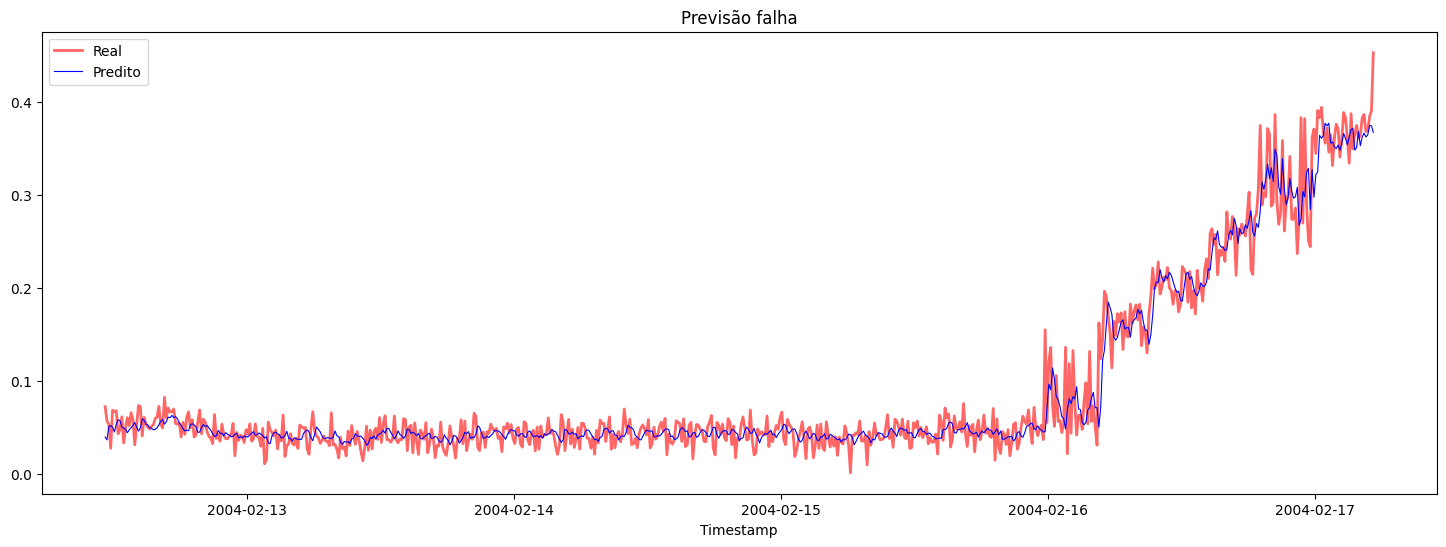

In [228]:
plt.figure(figsize=(18,6))
plt.plot(treino_timestamps_rolamento_1, y_treino_rolamento_1, color='red', linewidth=2.0, alpha=0.6)
plt.plot(treino_timestamps_rolamento_1, y_treino_pred_rolamento_1, color='blue', linewidth=0.8)
plt.legend(['Real','Predito'])
plt.xlabel('Timestamp')
plt.title('Previsão falha')
plt.show()

### Erro Percentual Absoluto Médio

In [219]:
mape_rolamento_1 = mean_absolute_percentage_error(y_treino_pred_rolamento_1, y_treino_rolamento_1) * 100

print('MAPE for training data: {:.2f}%'.format(mape_rolamento_1))

MAPE for training data: 23.41%


## Performance em todo o dataset

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:439: UserWarning:

X does not have valid feature names, but MinMaxScaler was fitted with feature names



Tensor shape:  (980, 5)
X shape:  (980, 4) 
Y_rolamento_1 shape:  (980, 1)


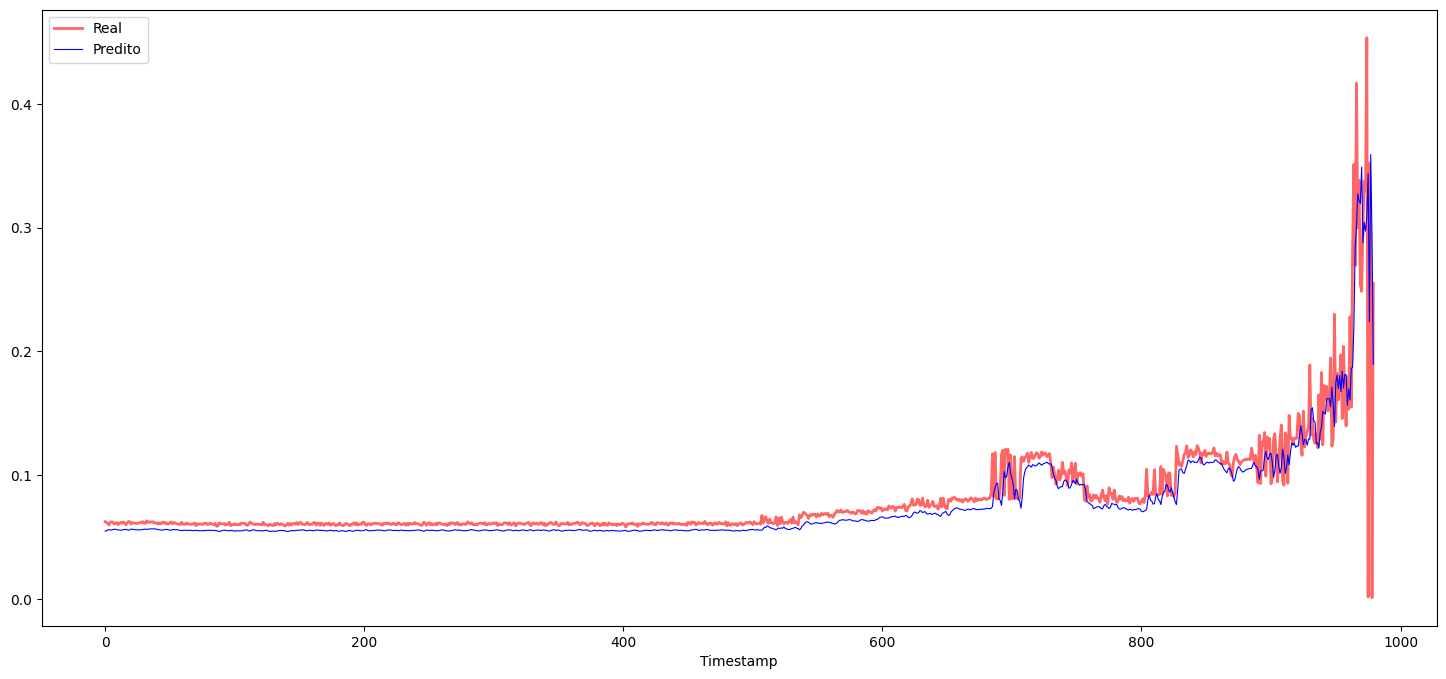

In [227]:
# Extracting load values as numpy array
data_rolamento_1 = df_rolamento_1.copy().values

# Scaling
data_rolamento_1 = scaler.transform(data_rolamento_1)

# Transforming to 2D tensor as per model input requirement
data_timesteps_rolamento_1 = np.array([[j for j in data_rolamento_1[i:i+timesteps]] for i in range(0, len(data_rolamento_1)-timesteps+1)])[:,:,0]
print('Tensor shape: ', data_timesteps_rolamento_1.shape)

# Selecting inputs and outputs from data
X, Y_rolamento_1 = data_timesteps_rolamento_1[:,:timesteps-1], data_timesteps_rolamento_1[:,[timesteps-1]]
print('X shape: ', X.shape,'\nY_rolamento_1 shape: ', Y.shape)

# Make model predictions
Y_pred_rolamento_1 = model_rolamento_1.predict(X).reshape(-1,1)

# Inverse scale and reshape
Y_pred_rolamento_1 = scaler.inverse_transform(Y_pred_rolamento_1)
Y_rolamento_1 = scaler.inverse_transform(Y_rolamento_1)
plt.figure(figsize=(18,8))
plt.plot(Y_rolamento_1, color = 'red', linewidth=2.0, alpha = 0.6)
plt.plot(Y_pred_rolamento_1, color = 'blue', linewidth=0.8)
plt.legend(['Real','Predito'])
plt.xlabel('Timestamp')
plt.show()

### Erro Percentual Absoluto Médio

In [225]:
mape_rolamento_1 = mean_absolute_percentage_error(Y_pred_rolamento_1, Y_rolamento_1) * 100

print('MAPE for training data: {:.2f}%'.format(mape_rolamento_1))

MAPE for training data: 11.00%
